In [ ]:
!pip install -q pandas matplotlib openpyxl numpy

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":        12,
    "axes.linewidth":   1.1,
    "mathtext.fontset": "dejavuserif",
    "savefig.dpi":      300,
})

# ---- energy window (all 5 sources present 3-20 MeV; we display 1-20) --------
E_MIN, E_MAX = 1.0, 20.0     # MeV

B_TO_MB   = 1000.0           # barns -> millibarns
EV_TO_MEV = 1e-6             # eV    -> MeV

# ---- ROBUST file finder: matches by keyword, ignores spaces/underscores -----
#  This is the fix for the "file not found" warnings: it does NOT depend on
#  exact file names. It looks for a signature word inside each filename.
def _norm(s):
    return s.lower().replace(" ", "").replace("_", "").replace("-", "")

def resolve(key):
    sigs = {"EXFOR": "exfor", "TENDL": "tendl", "ENDF": "endf",
            "JEFF": "jeff", "TALYS": "talys"}
    want = sigs[key]
    for fn in os.listdir("."):
        if fn.startswith("."):
            continue
        n = _norm(fn)
        # the JENDL/ENDF point file may be named with 'ebdf', 'endf', or 'jendl'
        if want in n or (key == "ENDF" and ("jendl" in n or "ebdf" in n)):
            return fn
    return None

In [ ]:
def parse_exfor(path):
    df = pd.read_csv(path)
    out = pd.DataFrame({
        "energy_MeV": pd.to_numeric(df["energy_MeV"], errors="coerce"),
        "xs_mb":      pd.to_numeric(df["cross_section_b"], errors="coerce") * B_TO_MB,
        "dE_MeV":     pd.to_numeric(df.get("d_energy_MeV", 0), errors="coerce").fillna(0),
        "dxs_mb":     pd.to_numeric(df.get("d_cross_section_b", 0), errors="coerce").fillna(0) * B_TO_MB,
        "author":     df.get("author", "Unknown").astype(str).str.strip(),
        "year":       pd.to_numeric(df.get("year", 0), errors="coerce").fillna(0).astype(int),
    })
    out = out.dropna(subset=["energy_MeV", "xs_mb"])
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0]
    out["label"] = out["author"] + " (" + out["year"].astype(str) + ")"
    return out.reset_index(drop=True)

def parse_tendl(path):
    """TENDL/YANDF export. Header lines start with '#' or '##' and may contain
    'E,xs'. Data are already MeV / mb."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip().strip(',').strip()
            if not s or s.startswith("#") or s.startswith('"'):
                continue
            if "e,xs" in s.lower() or s.lower().startswith("e,"):
                continue
            parts = [p for p in s.replace(";", ",").split(",") if p != ""]
            if len(parts) < 2:
                continue
            try:
                rows.append((float(parts[0]), float(parts[1])))
            except ValueError:
                continue
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)

def parse_endf(path):
    """JENDL/ENDF point file: 'E[eV]  Sig[b]  Interp'. eV->MeV, b->mb."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            parts = s.split()
            if len(parts) < 2:
                continue
            try:
                rows.append((float(parts[0]) * EV_TO_MEV, float(parts[1]) * B_TO_MB))
            except ValueError:
                continue
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)

def parse_jeff(path):
    df = pd.read_csv(path)
    if "Energy_MeV" in df.columns:
        e = pd.to_numeric(df["Energy_MeV"], errors="coerce")
    else:
        e = pd.to_numeric(df["Energy_eV"], errors="coerce") * EV_TO_MEV
    xs = pd.to_numeric(df["CrossSection_barns"], errors="coerce") * B_TO_MB
    out = pd.DataFrame({"energy_MeV": e, "xs_mb": xs}).dropna()
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0].sort_values("energy_MeV")
    return out.reset_index(drop=True)

def parse_talys(path):
    """TALYS xlsx: paired (E[MeV], sigma[mb]) blocks per ldmodel. Sub-threshold
    rows may contain '-' placeholders -> coerced to NaN and dropped.
    Uses ldmodel1 as the main curve."""
    raw = pd.read_excel(path, header=None)
    titles = raw.iloc[0].tolist()
    start_col = 0
    for i, t in enumerate(titles):
        if isinstance(t, str) and "ldmodel1" in t.replace(" ", "").lower():
            start_col = i
            break
    e  = pd.to_numeric(raw.iloc[2:, start_col],     errors="coerce")
    xs = pd.to_numeric(raw.iloc[2:, start_col + 1], errors="coerce")
    out = pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}).dropna()
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0].sort_values("energy_MeV")
    return out.reset_index(drop=True)

PARSERS = {"EXFOR": parse_exfor, "TENDL": parse_tendl, "ENDF": parse_endf,
           "JEFF": parse_jeff, "TALYS": parse_talys}

data = {}
for key, parser in PARSERS.items():
    path = resolve(key)
    if path is None:
        print(f"[WARNING] {key}: no matching file uploaded — skipping.")
        data[key] = None
        continue
    try:
        data[key] = parser(path)
        print(f"[OK] {key:5s}: {len(data[key]):4d} points  from '{path}'")
    except Exception as e:
        print(f"[ERROR] {key}: failed to parse '{path}': {e}")
        data[key] = None


[OK] EXFOR:  532 points  from 'Fe-56_n_p_Mn-56 exfor.csv'
[OK] TENDL:   33 points  from 'Fe56 tendl.csv'
[OK] ENDF :   81 points  from 'Copy of Fe 56 ( n,p ) cross section data ebdf.txt'
[OK] JEFF :   69 points  from 'JEFF_Fe56_np_CrossSection_1MeV_to_40MeV.csv'
[OK] TALYS:   55 points  from 'TALYS DATAfor Fe 56.csv.xlsx'


Saved plot -> Fe56_np_combined_comparison_plot.png


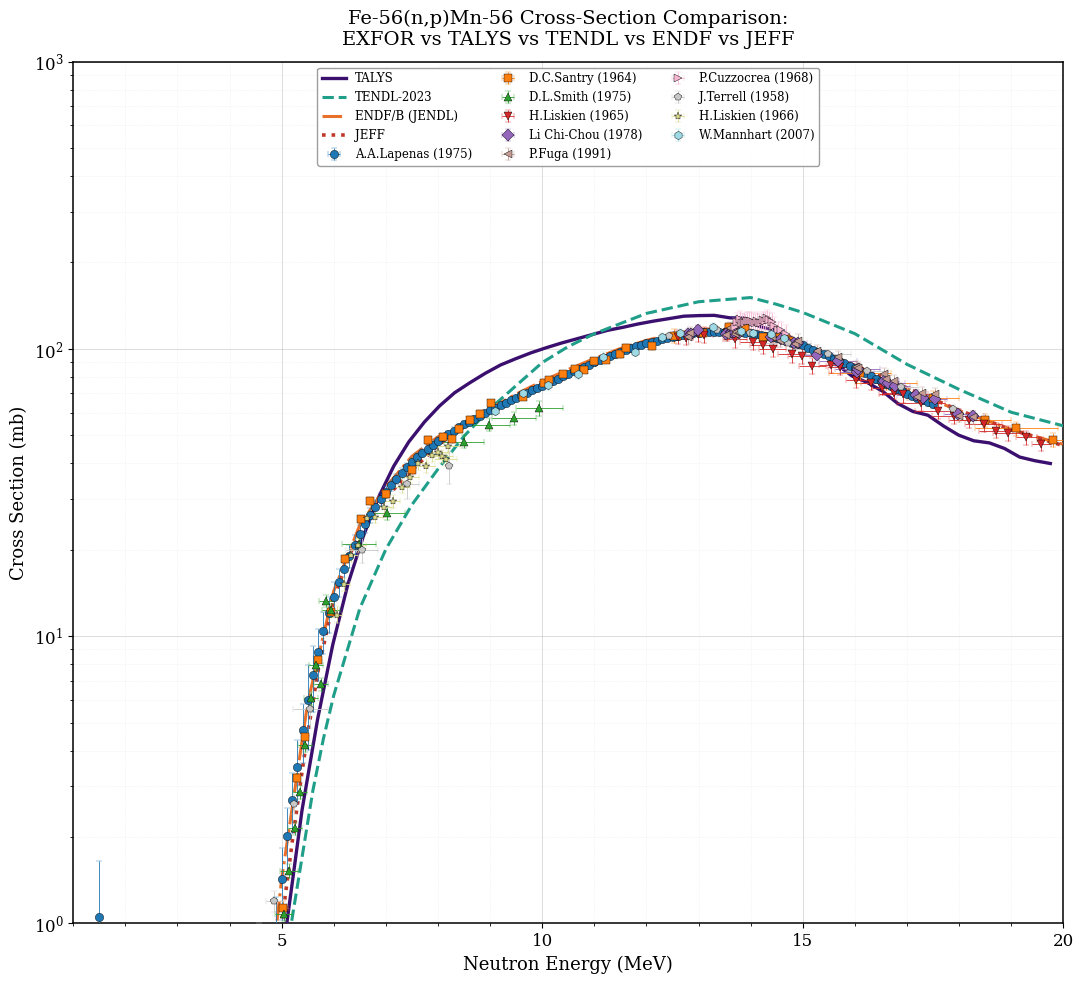

In [ ]:
# ---- imports (keep near your other imports) ---------------------------------
from matplotlib.ticker import LogLocator, MultipleLocator, NullFormatter

fig, ax = plt.subplots(figsize=(11, 10))

# ---- theoretical / evaluated curves -----------------------------------------
CURVE_STYLE = {
    "TALYS": dict(color="#3a0f6e", ls="-",  lw=2.4, label="TALYS"),
    "TENDL": dict(color="#1f9e89", ls="--", lw=2.2, label="TENDL-2023"),
    "ENDF":  dict(color="#e8702a", ls="-.", lw=2.2, label="ENDF/B (JENDL)"),
    "JEFF":  dict(color="#c0392b", ls=":",  lw=2.6, label="JEFF"),
}
for key in ["TALYS", "TENDL", "ENDF", "JEFF"]:
    df = data.get(key)
    if df is not None and len(df):
        ax.plot(df["energy_MeV"], df["xs_mb"], **CURVE_STYLE[key], zorder=3)

# ---- EXFOR experimental points, color-coded by author/year ------------------
exfor = data.get("EXFOR")
if exfor is not None and len(exfor):
    TOP_N = 10
    counts = exfor["label"].value_counts()
    top_labels = list(counts.index[:TOP_N])
    exfor = exfor.copy()

    # keep ONLY the top-N authors; drop everything else (no "Other measurements")
    exfor = exfor[exfor["label"].isin(top_labels)].copy()
    exfor["plot_label"] = exfor["label"]
    plot_labels = top_labels

    cmap = plt.cm.tab20(np.linspace(0, 1, max(len(plot_labels), 1)))
    markers = ["o", "s", "^", "v", "D", "<", ">", "p", "*", "h", "X", "P"]

    # darken the "Other measurements" entry (last label) for visibility
    # if plot_labels and plot_labels[-1] == "Other measurements":
    #     cmap[-1] = (0.35, 0.35, 0.35, 0.9)   # dark gray, mostly opaque

    for i, lab in enumerate(plot_labels):
        sub = exfor[exfor["plot_label"] == lab]
        ax.errorbar(
            sub["energy_MeV"], sub["xs_mb"],
            yerr=sub["dxs_mb"].where(sub["dxs_mb"] > 0, np.nan),
            xerr=sub["dE_MeV"].where(sub["dE_MeV"] > 0, np.nan),
            fmt=markers[i % len(markers)],
            color=cmap[i], ecolor=cmap[i],
            markersize=6, capsize=2, elinewidth=0.6, capthick=0.6,
            alpha=1.0, label=lab, zorder=4,
            markeredgecolor="black", markeredgewidth=0.3,
        )

# ---- axes scales and range --------------------------------------------------
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(E_MIN, E_MAX)            # 1–20 MeV
ax.set_ylim(1, 1000)                 # Fe-56 peak ~130 mb; headroom for legend

ax.set_xlabel("Neutron Energy (MeV)", fontsize=13)
ax.set_ylabel("Cross Section (mb)", fontsize=13)
ax.set_title(
    "Fe-56(n,p)Mn-56 Cross-Section Comparison:\n"
    "EXFOR vs TALYS vs TENDL vs ENDF vs JEFF",
    fontsize=14, pad=12,
)

# ---- X AXIS (linear): major ticks 5,10,15,20; minor every 1 -----------------
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))

# ---- Y AXIS (log): major decades 10,100,1000; minor sub-decade --------------
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_formatter(NullFormatter())

ax.grid(which="major", ls="-",  lw=0.6, alpha=0.5)
ax.grid(which="minor", ls=":",  lw=0.4, alpha=0.3)

ax.legend(loc="upper center", ncol=3, fontsize=8.5,
          framealpha=0.95, edgecolor="0.6")

fig.tight_layout()

OUT_PNG = "Fe56_np_combined_comparison_plot.png"
fig.savefig(OUT_PNG, dpi=600, bbox_inches="tight")
print(f"Saved plot -> {OUT_PNG}")

In [ ]:
frames = []
for key, df in data.items():
    if df is None or not len(df):
        continue
    tmp = df.copy()
    tmp["source"] = key
    if key == "EXFOR":
        tmp = tmp[["source", "energy_MeV", "xs_mb", "dE_MeV", "dxs_mb", "author", "year"]]
    else:
        tmp = tmp[["source", "energy_MeV", "xs_mb"]]
        tmp["dE_MeV"] = np.nan; tmp["dxs_mb"] = np.nan
        tmp["author"] = np.nan; tmp["year"] = np.nan
    frames.append(tmp)

# guard: clear message instead of a cryptic KeyError if nothing loaded
if not frames:
    raise RuntimeError(
        "No data loaded — every source was skipped. Check the [WARNING] lines "
        "from Cell 3 and confirm all 5 files are uploaded (Files panel)."
    )

combined = pd.concat(frames, ignore_index=True)
combined = combined.sort_values(["source", "energy_MeV"]).reset_index(drop=True)
OUT_CSV = "Fe56_np_parsed_data.csv"
combined.to_csv(OUT_CSV, index=False)
print(f"Saved data -> {OUT_CSV}  ({len(combined)} rows)")

OUT_TXT = "Fe56_np_summary_statistics.txt"
with open(OUT_TXT, "w") as f:
    f.write("Fe-56(n,p)Mn-56 Cross-Section Data — Summary Statistics\n")
    f.write("=" * 60 + "\n")
    f.write(f"Comparison energy window: {E_MIN}-{E_MAX} MeV\n\n")
    for key, df in data.items():
        f.write(f"[{key}]\n")
        if df is None or not len(df):
            f.write("  (no data / file missing)\n\n"); continue
        f.write(f"  points        : {len(df)}\n")
        f.write(f"  energy range  : {df['energy_MeV'].min():.4g} - {df['energy_MeV'].max():.4g} MeV\n")
        f.write(f"  xs min        : {df['xs_mb'].min():.4g} mb\n")
        f.write(f"  xs max        : {df['xs_mb'].max():.4g} mb\n")
        if key == "EXFOR":
            f.write(f"  unique authors: {df['author'].nunique()}\n")
            f.write(f"  year range    : {int(df['year'].min())}-{int(df['year'].max())}\n")
        f.write("\n")
print(f"Saved stats -> {OUT_TXT}")
print(open(OUT_TXT).read())


Saved data -> Fe56_np_parsed_data.csv  (770 rows)
Saved stats -> Fe56_np_summary_statistics.txt
Fe-56(n,p)Mn-56 Cross-Section Data — Summary Statistics
Comparison energy window: 1.0-20.0 MeV

[EXFOR]
  points        : 532
  energy range  : 1 - 19.87 MeV
  xs min        : 0.0002084 mb
  xs max        : 190 mb
  unique authors: 82
  year range    : 1951-2023

[TENDL]
  points        : 33
  energy range  : 3.4 - 20 MeV
  xs min        : 8.34e-09 mb
  xs max        : 151 mb

[ENDF]
  points        : 81
  energy range  : 3.866 - 20 MeV
  xs min        : 0.001 mb
  xs max        : 118.3 mb

[JEFF]
  points        : 69
  energy range  : 2.992 - 20 MeV
  xs min        : 2.459e-08 mb
  xs max        : 116 mb

[TALYS]
  points        : 55
  energy range  : 3.93 - 19.75 MeV
  xs min        : 0.0002706 mb
  xs max        : 130.9 mb




In [ ]:
plt.show()